In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
#Load dataset
df =pd.read_csv("day.csv")

In [5]:
df.head(5)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [8]:
df.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')

choose our features and target

In [10]:
X = df[[
    "temp",
    "hum",
    "windspeed",
    "season",
    "holiday",
    "workingday",
    "weathersit"
]]

y = df["cnt"]

Split into training and testing data:

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

Linear Regression:

In [12]:
model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [13]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[5130.81198924 2645.01020518 4016.92333675 3526.67253909 5730.13907096
 6318.28691714 1984.65658648 3135.32166308 6428.33432631 5426.02180045]


In [14]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 1149.3013835877089
MSE: 1817448.4478506406
RMSE: 1348.1277565018238
R²: 0.5467576559478816


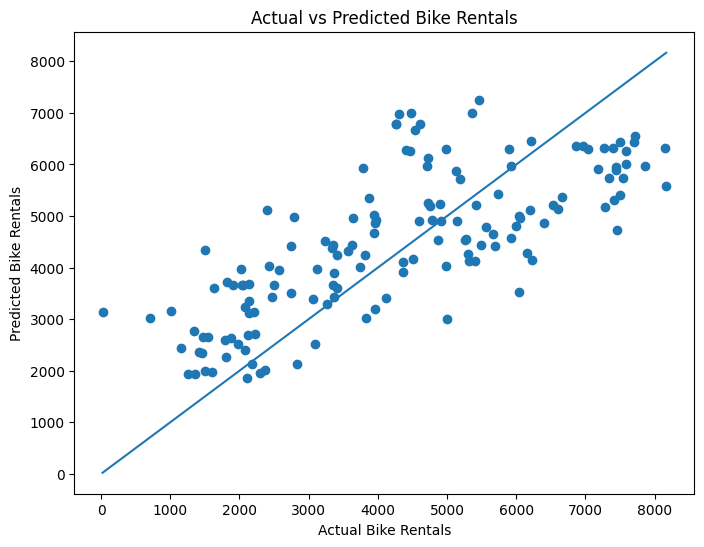

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.xlabel("Actual Bike Rentals")
plt.ylabel("Predicted Bike Rentals")
plt.title("Actual vs Predicted Bike Rentals")

plt.show()

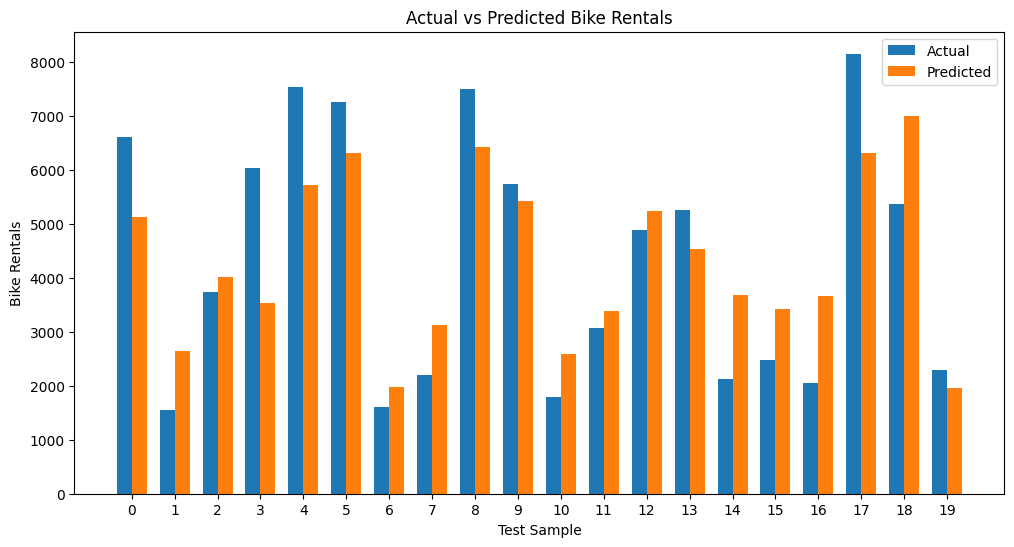

In [16]:
# Take first 20 observations
actual = y_test.iloc[:20].values
predicted = y_pred[:20]

x = np.arange(20)
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(x - width/2, actual, width, label="Actual")
plt.bar(x + width/2, predicted, width, label="Predicted")

plt.xlabel("Test Sample")
plt.ylabel("Bike Rentals")
plt.title("Actual vs Predicted Bike Rentals")
plt.xticks(x)
plt.legend()

plt.show()

   instant      dteday  season  yr  mnth  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1        0        6           0   
1        2  2011-01-02       1   0     1        0        0           0   
2        3  2011-01-03       1   0     1        0        1           1   
3        4  2011-01-04       1   0     1        0        2           1   
4        5  2011-01-05       1   0     1        0        3           1   

   weathersit      temp     atemp       hum  windspeed  casual  registered  \
0           2  0.344167  0.363625  0.805833   0.160446     331         654   
1           2  0.363478  0.353739  0.696087   0.248539     131         670   
2           1  0.196364  0.189405  0.437273   0.248309     120        1229   
3           1  0.200000  0.212122  0.590435   0.160296     108        1454   
4           1  0.226957  0.229270  0.436957   0.186900      82        1518   

    cnt  
0   985  
1   801  
2  1349  
3  1562  
4  1600  
Index(['instant', 'dteday'

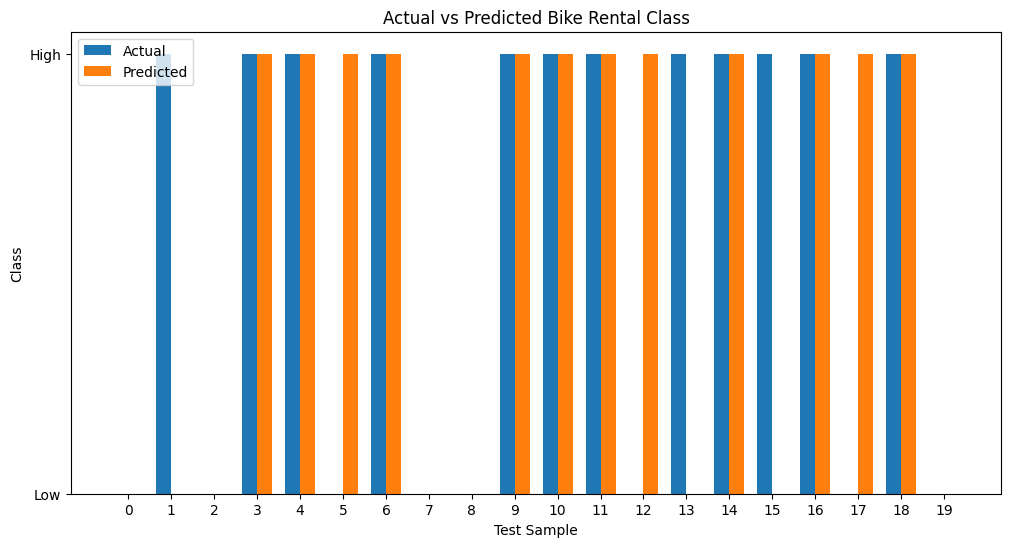

In [17]:
import pandas as pd
import numpy as np

# -----------------------------
# 1. Load dataset
# -----------------------------
df = pd.read_csv("day.csv")

print(df.head())
print(df.columns)


# -----------------------------
# 2. Create classification target
# -----------------------------
# Median rental count will separate:
# 0 = Low rentals
# 1 = High rentals

median_cnt = df["cnt"].median()

df["target"] = (df["cnt"] >= median_cnt).astype(int)

print("\nMedian rental count:", median_cnt)
print("\nTarget distribution:")
print(df["target"].value_counts())


# -----------------------------
# 3. Select features (X) and target (y)
# -----------------------------
X = df[[
    "temp",
    "hum",
    "windspeed",
    "season",
    "holiday",
    "workingday",
    "weathersit"
]]

y = df["target"]


# -----------------------------
# 4. Split into training/testing data
# -----------------------------
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# -----------------------------
# 5. Train Logistic Regression
# -----------------------------
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)


# -----------------------------
# 6. Make predictions
# -----------------------------
y_pred = model.predict(X_test)

print("\nFirst 20 predictions:")
print(y_pred[:20])


# -----------------------------
# 7. Evaluate the classifier
# -----------------------------
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


# -----------------------------
# 8. Plot actual vs predicted
# -----------------------------
import matplotlib.pyplot as plt

actual = y_test.iloc[:20].values
predicted = y_pred[:20]

x = np.arange(20)
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    actual,
    width,
    label="Actual"
)

plt.bar(
    x + width/2,
    predicted,
    width,
    label="Predicted"
)

plt.xlabel("Test Sample")
plt.ylabel("Class")
plt.title("Actual vs Predicted Bike Rental Class")
plt.xticks(x)
plt.yticks([0, 1], ["Low", "High"])
plt.legend()

plt.show()

In [18]:
from sklearn.datasets import load_iris

iris = load_iris()

print(iris.data[:5])
print(iris.target[:5])
print(iris.feature_names)
print(iris.target_names)

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]
[0 0 0 0 0]
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa' 'versicolor' 'virginica']


In [19]:
X = iris.data
y = iris.target

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (150, 4)
y shape: (150,)


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (120, 4)
X_test: (30, 4)
y_train: (120,)
y_test: (30,)


In [21]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=200)

model.fit(X_train, y_train)

LogisticRegression(max_iter=200)

In [22]:
model.fit(X_train, y_train)

LogisticRegression(max_iter=200)

In [23]:
y_pred = model.predict(X_test)

print(y_pred)
print(y_test)

[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


In [24]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9666666666666667


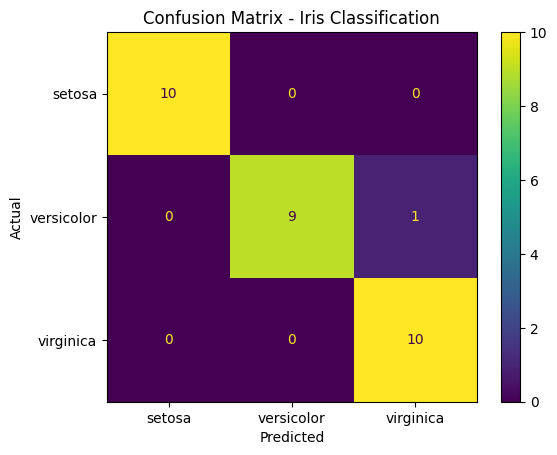

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot()

plt.title("Confusion Matrix - Iris Classification")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]
